# 04 FMA MLP: four Keras architectures, a learning-rate check, and comparison with the best classical model

In [1]:
import sys; sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder, StandardScaler
from src.config import FIGURES, SEED
from src.data import load_fma, fma_xy
from src.evaluate import evaluate, results_table, save_result

fma = load_fma()
X_train, y_train = fma_xy(fma, "training")
X_val, y_val = fma_xy(fma, "validation")
X_test, y_test = fma_xy(fma, "test")

# Scaler fitted on training only, then applied to validation and test.
scaler = StandardScaler().fit(X_train)
Xtr, Xva, Xte = (scaler.transform(X).astype("float32") for X in (X_train, X_val, X_test))
# LabelEncoder sorts genres alphabetically, the same order as le.classes_, so softmax column i is classes_[i].
le = LabelEncoder().fit(y_train)
ytr, yva = le.transform(y_train), le.transform(y_val)
Xtr.shape, list(le.classes_)

((6400, 518),
 ['Electronic',
  'Experimental',
  'Folk',
  'Hip-Hop',
  'Instrumental',
  'International',
  'Pop',
  'Rock'])

## 1. Four architectures

All use ReLU hidden layers, a softmax output, Adam, batch 64 and up to 200 epochs. EarlyStopping stops after 15 epochs without a lower validation loss and restores the best weights; ReduceLROnPlateau halves the learning rate after 5.

In [2]:
EPOCHS = 200
configs = {
    "256": dict(hidden=(256,)),
    "512-256": dict(hidden=(512, 256)),
    "512-256 dropout": dict(hidden=(512, 256), dropout=0.3),
    "512-256-128 dropout+L2": dict(hidden=(512, 256, 128), dropout=0.3, l2=1e-4),
}

def build(hidden, dropout=0.0, l2=0.0, lr=1e-3):
    tf.keras.utils.set_random_seed(SEED)  # same initial weights and shuffling for every run
    model = keras.Sequential([keras.Input((Xtr.shape[1],))])
    for units in hidden:
        # L2 adds l2 * sum(w^2) to the loss, pulling weights towards zero.
        model.add(keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        if dropout:
            model.add(keras.layers.Dropout(dropout))  # zeroes 30% of units at random each training step
    model.add(keras.layers.Dense(len(le.classes_), activation="softmax"))
    model.compile(keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train(cfg, lr=1e-3, X=None, y=None):
    X, y = (Xtr, ytr) if X is None else (X, y)
    model = build(**cfg, lr=lr)
    hist = model.fit(X, y, validation_data=(Xva, yva), epochs=EPOCHS, batch_size=64, verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=15, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=5, min_lr=1e-6)])
    proba = model.predict(Xva, verbose=0)
    m, _ = evaluate(y_val, le.classes_[proba.argmax(1)], proba, labels=le.classes_)
    return {"model": model, "history": hist.history, "params": model.count_params(),
            "epochs": len(hist.history["loss"]), "best_val_loss": min(hist.history["val_loss"]),
            "val_macro_f1": m["macro_f1"], "val_accuracy": m["accuracy"]}

runs = {}
for name, cfg in configs.items():
    runs[name, 1e-3] = train(cfg)
    print(f"{name:24s} val macro-F1 {runs[name, 1e-3]['val_macro_f1']:.4f}  epochs {runs[name, 1e-3]['epochs']}")

256                      val macro-F1 0.5348  epochs 17


512-256                  val macro-F1 0.4944  epochs 16


512-256 dropout          val macro-F1 0.5313  epochs 17


512-256-128 dropout+L2   val macro-F1 0.5239  epochs 19


## 2. Learning-rate check on the best architecture

In [3]:
best_cfg = max(configs, key=lambda n: runs[n, 1e-3]["val_macro_f1"])
for lr in (1e-2, 1e-4):
    runs[best_cfg, lr] = train(configs[best_cfg], lr)
print("Best architecture:", best_cfg)

Best architecture: 256


## 3. Comparison table (validation only)

In [4]:
cols = ["params", "epochs", "best_val_loss", "val_accuracy", "val_macro_f1"]
table = pd.DataFrame({k: {c: r[c] for c in cols} for k, r in runs.items()}).T.rename_axis(["config", "lr"])
selected = table["val_macro_f1"].astype(float).idxmax()
print("Selected on validation macro-F1:", selected)
table.round(4)

Selected on validation macro-F1: ('256', np.float64(0.0001))


params  epochs  best_val_loss  val_accuracy  \
config                 lr                                                      
256                    0.0010  134920.0    17.0         1.4537        0.5350   
512-256                0.0010  399112.0    16.0         1.4333        0.5088   
512-256 dropout        0.0010  399112.0    17.0         1.3293        0.5425   
512-256-128 dropout+L2 0.0010  430984.0    19.0         1.4200        0.5275   
256                    0.0100  134920.0    16.0         1.6270        0.4888   
                       0.0001  134920.0    34.0         1.3531        0.5713   

                               val_macro_f1  
config                 lr                    
256                    0.0010        0.5348  
512-256                0.0010        0.4944  
512-256 dropout        0.0010        0.5313  
512-256-128 dropout+L2 0.0010        0.5239  
256                    0.0100        0.5038  
                       0.0001        0.5655

## 4. Loss curves: overfitting and its fix

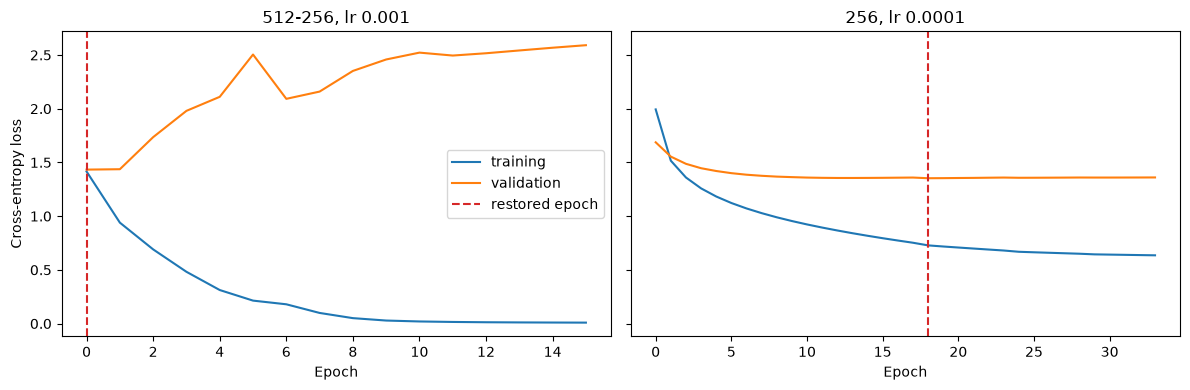

In [5]:
# The no-dropout (512, 256) run against the selected run (or the dropout run, if no-dropout was selected).
other = selected if selected != ("512-256", 1e-3) else ("512-256 dropout", 1e-3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, key in zip(axes, [("512-256", 1e-3), other]):
    h = runs[key]["history"]
    ax.plot(h["loss"], label="training")
    ax.plot(h["val_loss"], label="validation")
    ax.axvline(int(np.argmin(h["val_loss"])), color="tab:red", ls="--", label="restored epoch")
    ax.set(title=f"{key[0]}, lr {key[1]:g}", xlabel="Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "fma_mlp_loss_curves.png", dpi=200)

## 5. Test (once) and comparison with the best classical model (H2)

In [6]:
best = runs[selected]
proba = best["model"].predict(Xte, verbose=0)
metrics, per_class = evaluate(y_test, le.classes_[proba.argmax(1)], proba, labels=le.classes_)
cfg = configs[selected[0]]
save_result("mlp", "fma", metrics, params={"hidden": list(cfg["hidden"]), "dropout": cfg.get("dropout", 0.0),
            "l2": cfg.get("l2", 0.0), "lr": selected[1], "epochs": best["epochs"], "n_params": best["params"]})
results_table("fma")[["accuracy", "macro_f1", "mcc", "macro_auc_ovr"]]

,accuracy,macro_f1,mcc,macro_auc_ovr
model,,,,
random_forest,0.4900,0.4867,0.4175,0.8280
mlp,0.4650,0.4625,0.3888,0.8111
logistic_regression,0.4512,0.4494,0.3731,0.8131
decision_tree,0.3625,0.3598,0.2719,0.7398
naive_bayes,0.3713,0.3494,0.2866,0.7810
knn,0.2975,0.2938,0.1988,0.6660
zeror,0.1250,0.0278,0.0000,0.5000


In [7]:
per_class.sort_values("recall_tpr")

,precision,recall_tpr,fpr,f1,support
Folk,0.2118,0.18,0.0957,0.1946,100
Experimental,0.3878,0.38,0.0857,0.3838,100
Pop,0.3248,0.38,0.1129,0.3502,100
Instrumental,0.4286,0.42,0.0800,0.4242,100
International,0.5521,0.53,0.0614,0.5408,100
Electronic,0.5567,0.54,0.0614,0.5482,100
Rock,0.5816,0.57,0.0586,0.5758,100
Hip-Hop,0.6486,0.72,0.0557,0.6825,100


H2 predicts the MLP gives at most a small gain over the best classical model. Compare the `mlp` row with the best other row above.

## 6. Overfitting experiment: Classifiers 1, 2 and 3

The selected configuration is retrained after moving 0%, 30% and 60% of the training split into the test split (stratified by genre). Less training data should lower test accuracy and widen the train-test gap. Validation is unchanged and still drives early stopping. This is a diagnostic, so these runs are not saved as results.

FMA's split keeps each artist in one split, but the moved tracks share artists with the tracks left in training, so accuracy on the moved part is optimistic. `orig_test_acc` scores the original 800 test tracks only, which is the fair comparison across the three classifiers.

,train_size,test_size,epochs,train_acc,test_acc,orig_test_acc,gap
classifier,,,,,,,
Classifier 1,6400,800,34,0.7850,0.4650,0.4650,0.3200
Classifier 2,4480,2720,30,0.7513,0.5401,0.4538,0.2976
Classifier 3,2560,4640,32,0.7559,0.5254,0.4325,0.3234


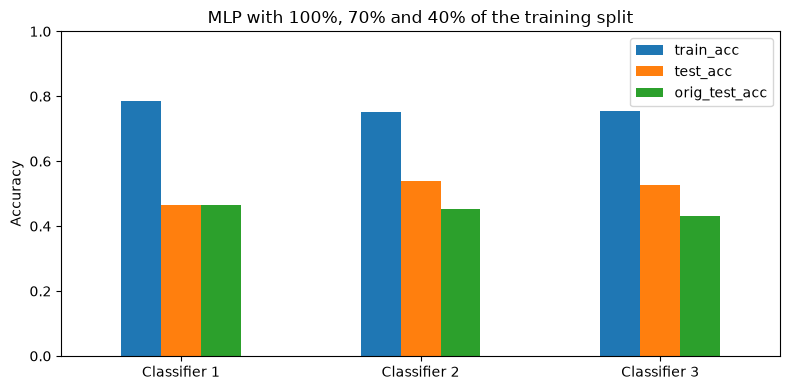

In [8]:
from sklearn.model_selection import train_test_split
yte = le.transform(y_test)
rows = []
for i, frac in enumerate([0.0, 0.3, 0.6], 1):
    if frac:
        Xfit, Xmove, yfit, ymove = train_test_split(Xtr, ytr, test_size=frac, stratify=ytr, random_state=SEED)
        r = train(configs[selected[0]], selected[1], Xfit, yfit)
        Xeval, yeval = np.vstack([Xte, Xmove]), np.concatenate([yte, ymove])
    else:
        Xfit, yfit, Xeval, yeval, r = Xtr, ytr, Xte, yte, best  # Classifier 1 is the selected model itself
    acc = lambda X, y: float((r["model"].predict(X, verbose=0).argmax(1) == y).mean())
    rows.append({"classifier": f"Classifier {i}", "train_size": len(yfit), "test_size": len(yeval),
                 "epochs": r["epochs"], "train_acc": acc(Xfit, yfit), "test_acc": acc(Xeval, yeval),
                 "orig_test_acc": acc(Xte, yte)})
over = pd.DataFrame(rows).set_index("classifier")
over["gap"] = over["train_acc"] - over["orig_test_acc"]

ax = over[["train_acc", "test_acc", "orig_test_acc"]].plot.bar(rot=0, figsize=(8, 4))
ax.set(ylabel="Accuracy", xlabel="", ylim=(0, 1),
       title="MLP with 100%, 70% and 40% of the training split")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "fma_mlp_overfitting.png", dpi=200)
over.round(4)

## Findings

- **Architectures (validation macro-F1):** 256 reached 0.5348, 512-256 reached 0.4944, 512-256 with dropout reached 0.5313 and 512-256-128 with dropout and L2 reached 0.5239. The single hidden layer of 256 was best, so extra width and depth did not help. Dropout lifted the 512-256 network from 0.4944 to 0.5313 and gave the lowest validation loss of the four (1.329), so regularisation matters more than size. All four stopped early, after 16-19 epochs.
- **Learning rate (on the 256 network):** 1e-2 was worse (0.5038 validation macro-F1, validation loss 1.627). 1e-4 was best (0.5655 validation macro-F1, validation loss 1.353) but needed 34 epochs against 17 at 1e-3. Selection used validation only, so the chosen MLP is 256 hidden units at learning rate 1e-4.
- **Loss curves:** the unregularised 512-256 network has its lowest validation loss at the first epoch and then validation loss climbs from about 1.4 to about 2.6, while training loss falls to almost 0. This is severe overfitting. The selected 256 network at 1e-4 has a much smaller gap: validation loss flattens at about 1.35 from around epoch 10 and training loss ends at about 0.63. The right panel shows the effect of the smaller learning rate and smaller network rather than dropout alone, because the dropout run is not plotted.
- **Test result and H2:** the selected MLP scored 0.4625 macro-F1, 0.3888 MCC and 0.8111 macro-AUC on test. The random forest scored 0.4867, 0.4175 and 0.8280, so the MLP is 0.024 macro-F1 below the best classical model. It is above logistic regression (0.4494) and the other baselines. H2 predicts at most a small gain for the MLP, and there was no gain: it did not beat the random forest, so the "small gain" part of H2 is not supported. A likely reason is that 6,400 training tracks with 518 correlated features suit tree ensembles better than a neural network, and validation is only 800 tracks, so the choice of configuration is noisy.
- **Lowest-recall genres:** for the MLP these are Folk (0.18), Experimental (0.38) and Pop (0.38). The random forest's lowest were Folk (0.24), Experimental (0.31) and Pop (0.42), so the same three genres are hardest for both models and Folk is the worst for both. This again partly supports H1 (Experimental and Pop match, Folk replaces International). Hip-Hop is the easiest for the MLP (recall 0.72).
- **Overfitting experiment:** training accuracy was 0.785, 0.751 and 0.756 for Classifiers 1, 2 and 3 (training sizes 6400, 4480 and 2560). Accuracy on the original 800 test tracks fell from 0.465 to 0.454 to 0.433, which matches the prediction that less training data lowers fair test accuracy. The train-test gap on the original test set was 0.320, 0.298 and 0.323, so it did not widen steadily and the second part of the prediction is not supported. Accuracy on the full enlarged test set went up instead (0.465, 0.540, 0.525), because the tracks moved into test share artists with the tracks left in training. This number is optimistic and should not be used to compare the classifiers.
